<img src="https://www.anped.org.br/sites/default/files/images/ufcg-lateral.png" width="780" height="240" align="center"/>

## Centro de Engenharia Elétrica e Informática
## Departamento de Engenharia Elétrica
## Disciplina: <span style="color:red">Int. ao Processamento de Imagem Digital e Visão Computacional</span>
## Professora: <span style="color:red">Luciana Veloso</span>
## Aluno(a): <span style="color:red">Alysson Machado de Oliveira Barbosa</span>

# <span style="color:brown">Experimento 04: Morfologia Matemática</span>
***

### Sumário de Conteúdos

* [0. Importação dos Pacotes](#0)
* [1. Operações Lógicas em Imagens Binárias](#1)
* [2. Transformações Lineares](#2)
* [3. Dilatação e Erosão](#3)
* [4. Abertura e Fechamento](#4)

## <span style="color:brown">0. Importação dos Pacotes</span> <a class="anchor" id="0"></a>
***

In [1]:
import os                            # Operational System para manipulação de arquivos.
import cv2                           # OpenCV para manipulação de imagens.
import numpy as np                   # Numpy para manipulação de matrizes e arrays.
import matplotlib.pyplot as plt      # Pyplot para plotagem de gráficos e imagens.
import skimage.morphology            # Scikit-Image para produzir elementos estruturantes
%matplotlib inline

O Scikit-Image pode ser instalado com: `conda install scikit-image`.

## <span style="color:brown">1. Operações Lógicas em Imagens Binárias</span> <a class="anchor" id="1"></a>
***

É possível submeter imagens a operações lógicas de modo a obter novas imagens. Nesse contexto, a biblioteca OpenCV disponibiliza um conjunto de funções para implementação dessas operações:

1. AND: **C = A $\cap$ B**   
    * `C = cv2.bitwise_and( A, B )`
2. OR: $C = A \cup B$   
    * `C = cv2.bitwise_or( A, B )`
3. XOR: $C = A \oplus B$   
    * `C = cv2.bitwise_xor( A, B )`
4. Not: $C = \overline{A}$   
    * `C = ~A`
5. Diferença: $C = A \cap \overline{B} $   
    *  `C = A - B` 
    
    
**Obs:** a função `cv2.threshold( src_img, limiar, vmax, cv2.THRESH_BINARY)` pode ser utilizada para binarizar imagens de tipo `uint`, sendo necessário informar o limiar de binarização e o valor do nível alto. A função retorna o limiar utilizado e a imagem binarizada, com pixels de nível alto setados para `vmax` e os demais para 0.

* <span style="color:blue">**a. Carregue as imagens “A.tif” e “B.tif”. Binarize as imagens e realize as operações abaixo:**</span>

    * <span style="color:blue">1. $A$ </span>  
    * <span style="color:blue">2. $B$ </span>  
    * <span style="color:blue">3. $C = A \cap B$ </span>  
    * <span style="color:blue">4. $D = A - B$ </span>  
    * <span style="color:blue">5. $E = \overline{A}$ </span>   
    * <span style="color:blue">6. $F = \overline{B}$ </span>  
    * <span style="color:blue">7. $G = A \cup B$ </span>  
    * <span style="color:blue">8. $H = B - A$ </span>  
    * <span style="color:blue">Comente os resultados encontrados.</span>

Text(0.5, 0, 'Dimensões (313, 316)')

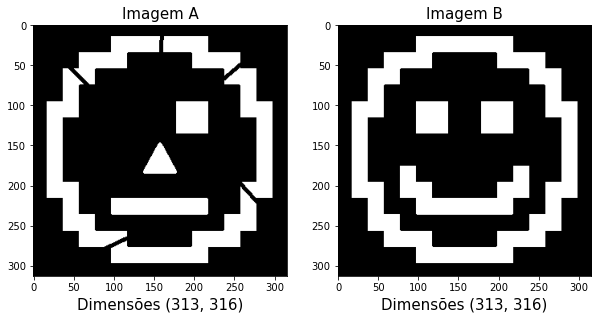

In [2]:
# carregando as imagens e convertendo-as para a escala de cinza
ima = cv2.imread('images/A.tif')
ima = cv2.cvtColor(ima, cv2.COLOR_BGR2GRAY)
imb = cv2.imread('images/B.tif')
imb = cv2.cvtColor(imb, cv2.COLOR_BGR2GRAY)

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize=(10, 10))

# primeira figura da subplotagem
axs[0].imshow(ima, cmap='gray', vmin=np.min(ima), vmax=np.max(ima))
axs[0].set_title('Imagem A', size=15)
axs[0].set_xlabel('Dimensões ' + str(ima.shape), size=15)

# segunda figura da subplotagem 
axs[1].imshow(imb, cmap='gray', vmin=np.min(imb), vmax=np.max(imb))
axs[1].set_title('Imagem B', size=15)
axs[1].set_xlabel('Dimensões ' + str(imb.shape), size=15) 

Text(0.5, 0, 'Dimensões (313, 316)')

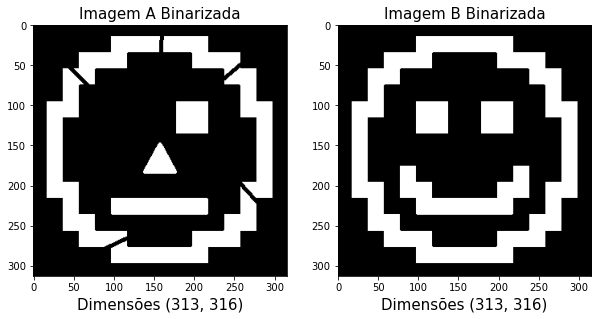

In [3]:
# aplicando a binarização nas imagens carregadas
ima_bin = cv2.threshold( ima, 127.5, 255, cv2.THRESH_BINARY)[1]
imb_bin = cv2.threshold( imb, 127.5, 255, cv2.THRESH_BINARY)[1]

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize=(10, 10))

# primeira figura da subplotagem
axs[0].imshow(ima_bin, cmap='gray', vmin=np.min(ima_bin), vmax=np.max(ima_bin))
axs[0].set_title('Imagem A Binarizada', size=15)
axs[0].set_xlabel('Dimensões ' + str(ima_bin.shape), size=15)

# segunda figura da subplotagem
axs[1].imshow(imb_bin, cmap='gray', vmin=np.min(imb_bin), vmax=np.max(imb_bin))
axs[1].set_title('Imagem B Binarizada', size=15)
axs[1].set_xlabel('Dimensões ' + str(imb_bin.shape), size=15) 

Text(0.5, 0, 'Dimensões (313, 316)')

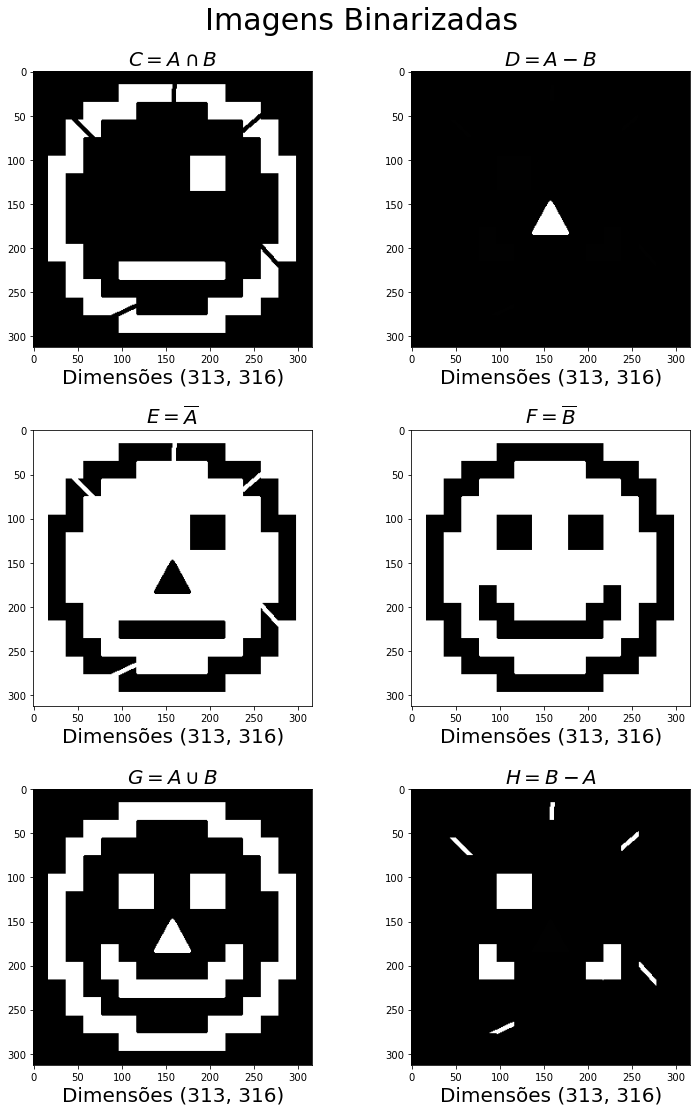

In [4]:
# operação lógica 3
imc = cv2.bitwise_and(ima_bin, imb_bin)
# operação lógica 4
imd = ima_bin - imb_bin
# operação lógica 5
ime = ~ima_bin 
# operação lógica 6
imf = ~imb_bin 
# operação lógica 7
img = cv2.bitwise_or(ima_bin, imb_bin)
# operação lógica 8
imh = imb_bin - ima_bin  

fig, axs = plt.subplots(nrows = 3, ncols = 2, figsize=(15, 15))
plt.subplots_adjust(left=0, bottom=0, right=0.7, top=0.92, wspace=0, hspace=0.3)
fig.suptitle('Imagens Binarizadas',size=30, x=0.35)

# primeira figura da subplotagem
axs[0,0].imshow(imc, cmap='gray', vmin=np.min(imc), vmax=np.max(imc))
axs[0,0].set_title('$C = A \cap B$', size=20)
axs[0,0].set_xlabel('Dimensões ' + str(imc.shape), size=20)

# segunda figura da subplotagem
axs[0,1].imshow(imd, cmap='gray', vmin=np.min(imd), vmax=np.max(imd))
axs[0,1].set_title('$D = A - B$ ', size=20)
axs[0,1].set_xlabel('Dimensões ' + str(imd.shape), size=20)

# terceira figura da subplotagem
axs[1,0].imshow(ime, cmap='gray', vmin=np.min(ime), vmax=np.max(ime))
axs[1,0].set_title('$E = \overline{A}$', size=20)
axs[1,0].set_xlabel('Dimensões ' + str(ime.shape), size=20)

# quarta figura da subplotagem
axs[1,1].imshow(imf, cmap='gray', vmin=np.min(imf), vmax=np.max(imf))
axs[1,1].set_title('$F = \overline{B}$', size=20)
axs[1,1].set_xlabel('Dimensões ' + str(imf.shape), size=20)

# quinta figura da subplotagem
axs[2,0].imshow(img, cmap='gray', vmin=np.min(img), vmax=np.max(img))
axs[2,0].set_title('$G = A \cup B$', size=20)
axs[2,0].set_xlabel('Dimensões ' + str(img.shape), size=20)

# sexta figura da subplotagem
axs[2,1].imshow(imh, cmap='gray', vmin=np.min(imh), vmax=np.max(imh))
axs[2,1].set_title('$H = B - A$', size=20)
axs[2,1].set_xlabel('Dimensões ' + str(imh.shape), size=20) 

* <span style="color:green">- Observando os resultados de cada uma das imagens, é possível destacar que:

    * <span style="color:green">1. $A$: Imagem A binarizada.</span>  
    * <span style="color:green">2. $B$: Imagem B binarizada.</span>  
    * <span style="color:green">3. $C = A \cap B$: Pixels altos de A binarizada e pixels altos de B binarizada compostos pela intersecção dos seus valores. Como a imagem A binarizada está parcialmente contida em B binarizada (exceto pelo triângulo que sugere ser um nariz), temos que a saída é A binarizada sem o triângulo na região do nariz.</span>    
    * <span style="color:green">4. $D = A - B$: Pixels da imagem A binarizada subtraídos dos pixels da imagem B binarizada. Como a única região de pixels com valores altos de A é a que forma um triângulo, e essa não está presente nos pixels B binarizada (como visto no procedimento 3), os pixels dessa região será o resultado da subtração realizada. </span>    
    * <span style="color:green">5. $E = \overline{A}$: Pixels com valores altos da imagem A binarizada passam a ter valores baixos e vice-versa.</span>  
    * <span style="color:green">6. $F = \overline{B}$: Pixels com valores altos da imagem B binarizada passam a ter valores baixos e vice-versa.</span>  
    * <span style="color:green">7. $G = A \cup B$: A união dos pixels da imagem A binarizada com os pixels da imagem B binarizada. Como saída dessa operação, foi obtido todos os pixels altos da Imagem B binarizada com os pixels que formam um triângulo da imagem A binarizada.</span>  
    * <span style="color:green">8. $H = B - A$: Semelhante ao procedimento 4, mas agora mudando a ordem dos fatores, temos uma mudança no resultado, visto que a subtração não é uma operação comutativa. Tendo em visto isso, o resultado desse procedimento é todos os valores de pixels altos presentes na imagem B binarizada que não estão presentes na imagem A binarizada.</span>  

* <span style="color:blue">**b. O código abaixo aplica uma das máscaras binárias da questão anterior sobre uma imagem. Com relação à imagem resultante, responda:**</span>  
 * <span style="color:blue">Qual o efeito de aplicar uma máscara binária sobre uma imagem?</span>  
 * <span style="color:blue">Cite pelo menos duas possíveis aplicações dessa operação. Qual o papel das máscaras nessas aplicações?</span>  
 * <span style="color:blue">Tendo em vista a quantidade de tons de cinza na máscara, qual a importância do tipo de interpolação utilizado?</span>  

Text(0.5, 1.0, 'Imagem Resultante')

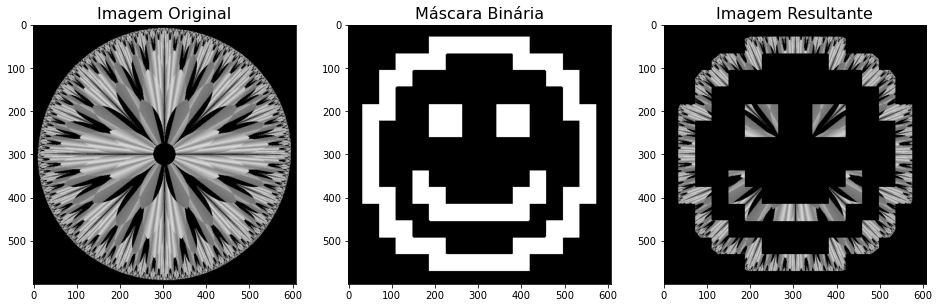

In [5]:
# Imagem Mandala
mandala = cv2.imread( os.path.join(".", "images", "mandala.jpg"), 0 )
H, W = mandala.shape

# Imagem B
B = cv2.imread( os.path.join(".", "images", "B.tif"), 0 )
_, B = cv2.threshold(B, 127, 255, cv2.THRESH_BINARY)
B_resized = cv2.resize(B, (W, H), interpolation = cv2.INTER_NEAREST)

# Imagem D
combined = cv2.bitwise_and( mandala, B_resized )

# Plotagem
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 8))

# Primeira Subfigura da Primeira Linha
axs[0].imshow(mandala, vmin=0, vmax=255, cmap="gray")
axs[0].set_title("Imagem Original", fontsize = 16)

# Segunda Subfigura da Primeira Linha
axs[1].imshow(B_resized, vmin=0, vmax=255, cmap="gray")
axs[1].set_title("Máscara Binária", fontsize = 16)

# Terceira Subfigura da Primeira Linha
axs[2].imshow(combined, vmin=0, vmax=255, cmap="gray")
axs[2].set_title("Imagem Resultante", fontsize = 16)

* <span style="color:green">A aplicação de mascáras binárias em imagens permite destacar determinadas regiões conhecidas na imagem. Desse modo, apenas as informações relevantes serão visualizáveis e as não importantes ocultadas.</span>
* <span style="color:green">Adição de personagens em cenários nos jogos 2D: a função da máscara binária nessa aplicação é juntar imagens de personagens do game com diversos cenários, dando a sensação de diversidade das fases ao jogador (Ver Figura 1);</span>
* <span style="color:green">Segmentação de objetos em imagens: uma forma interessante de segmentação de imagens utilizando redes neurais convolucionais é utilizar modelos que predizem máscaras binárias sobre a classe em análise (a exemplo a Mask R-CNN - Ver Figura 2);</span>
* <span style="color:green">A interpolação exerce uma fundamental importância na hora de redimensionar a imagem, pois esse procedimento permite usar dados conhecidos (os pixels da imagem em sua dimensão original) para estimar dados desconhecidos, esses que são resultados no processo de aumentar ou diminuir uma imagem. No exemplo analisado, a imagem foi ampliada e o tipo de interpolação utilizada usa os pixels vizinhos para estimar a localização de novos pixels, permitindo com que a imagem mantenha a mesma qualidade, principalmente ao se considerar a baixa quantidade de tons de cinza na máscara gerada. </span>

![Figura 1](https://user-images.githubusercontent.com/58775072/130303316-6dd469ab-f55e-4463-a03a-a2a1b736be7b.png)
> Figura 1: Adição de personagens em cenários nos jogos 2D.

![Figura 2](https://user-images.githubusercontent.com/58775072/130303217-e7701b80-04d3-42cf-beef-91a55ac59186.png)
> Figura 2: Uma visualização da Mask R-CNN produzindo máscaras 15x15, a máscara foi redimensionada para as dimensões originais de imagem em análise e sobreposta nela. (Fonte: [Deep Learning for Computer Vision with Python](https://pyimagesearch.com/deep-learning-computer-vision-python-book/), ImageNet Bundle).

Text(0.5, 0, 'Flor + Fractais')

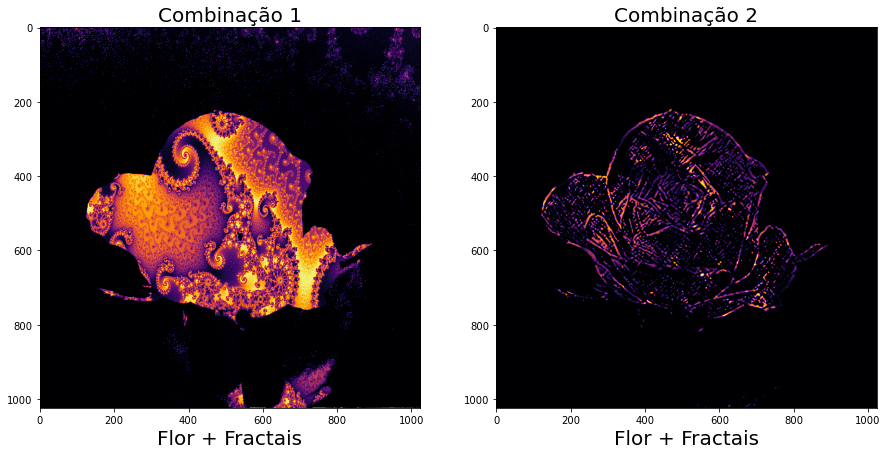

In [6]:
# carregando a primeira imagem na escala de cinza
head = cv2.imread('images/flower.jpg')
head = cv2.cvtColor(head, cv2.COLOR_BGR2GRAY)
head_b = cv2.threshold(head, 20, 255, cv2.THRESH_BINARY)[1]

# carregando a segunda imagem na escala de cinza
art = cv2.imread('images/fractal.jpg')
art = cv2.cvtColor(art, cv2.COLOR_BGR2GRAY)
# redimensionado a segunda imagem para as dimensões da primeira imagem usando interpolação  
art_r = cv2.resize(art, (head.shape[1], head.shape[0]), interpolation = cv2.INTER_NEAREST)

# combinando as duas imagens usando operador lógico 
combin1 = cv2.bitwise_and(head_b, art_r)

# aplicando uma série de procedimentos vistos em PDI para gerar uma arte com as duas imagens carregadas
img_blur = cv2.GaussianBlur(head, (3,3), 0)
sobelx = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=1, dy=0, ksize=5)
sobely = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=0, dy=1, ksize=5)
sobelxy = cv2.Sobel(src=img_blur, ddepth=cv2.CV_64F, dx=1, dy=1, ksize=5)
sobelxy_b = cv2.threshold(sobelxy, 15, 255, cv2.THRESH_BINARY)[1]
combin2 = cv2.bitwise_and(sobelxy_b.astype('uint8'), art_r)
combin2 = cv2.medianBlur(combin2, 5)

fig, axs = plt.subplots(nrows = 1, ncols = 2, figsize=(15, 15))

# primeira imagem da subplotagem
axs[0].imshow(combin1, cmap='inferno', vmin=np.min(combin1), vmax=np.max(combin1))
axs[0].set_title('Combinação 1', size=20)
axs[0].set_xlabel('Flor + Fractais', size=20)  

# segunda imagem da subplotagem
axs[1].imshow(combin2, cmap='inferno', vmin=np.min(combin2), vmax=np.max(combin2))
axs[1].set_title('Combinação 2', size=20)
axs[1].set_xlabel('Flor + Fractais', size=20)

## <span style="color:brown">2. Transformações Lineares</span> <a class="anchor" id="2"></a>
***

Também é possível realizar transformações lineares como rotação e translação com o OpenCV. Para isso, faz-se uso da função **warpAffine**.

`dst_img = cv2.warpAffine(src_img, M, (cols, rows))`

Descrição:  
* **dst_img** representa a imagem de saída;
* **src_img** representa a imagem de entrada;
* **M** corresponde à matriz de transformação utilizada;
* **rows** corresponde ao número de linhas da imagem;
* **cols** corresponde ao número de colunas da imagem;

Alguns exemplos de transformações que podem ser produzidas a partir desta função são:

1. Translações:
    * Para transladar a imagem Tx pixels para a direita e Ty pixels para baixo, faz-se uso de uma matriz com forma: 
    * **M = [ [1, 0, Tx], [0, 1, Ty] ]**
2. Rotações:
    * A matriz de transformação para uma rotacão de $\theta$ graus com relação ao ponto (Px, Py) pode ser obtida utilizando a função **getRotationMatrix2D**: 
    * `M = cv2.getRotationMatrix2D( (Px, Py), $\theta$, scale)`
3. Reflexão:
    * A imagem pode ser refletida utilizando as seguintes matrizes: 
    * **M = [ [-1, 0, cols-1], [0, 1, 0] ]**
    * **M = [ [1, 0, 0], [0, -1, rows-1] ]**

* <span style="color:blue">**c. O código abaixo implementa algumas das transformações descritas. Comente todas as linhas desse código e explique o que o programa faz.**</span>
 * <span style="color:blue">Que transformações são implementadas pelas matrizes Ma, Mb, Mc e Md?</span>
 * <span style="color:blue">As imagens 2 e 4 são diferentes apesar de terem sofrido as mesmas transformações. Por que isso aconteceu?</span>

Text(0.5, 1.0, 'Imagem 6')

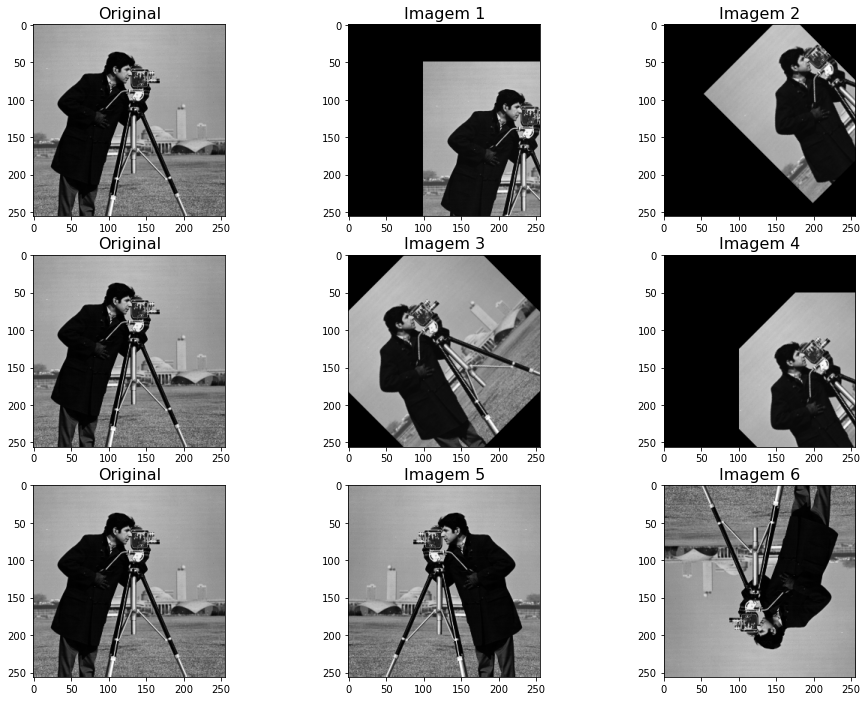

In [7]:
# configurando o parâmetro que permite transladar 100 pixels para a direita
Tx    = 100
# configurando o parâmetro que permite transladar 50 pixels para baixo
Ty    =  50
# configurando o parâmetro de rotação da imagem a 45 graus.
theta =  45

# encontrando a imagem de análise no diretório correspondente
src_img = cv2.imread(os.path.join(".", "images", "cameraman.jpg"),0)
# obtendo a quantidade de linhas e colunas da matriz de pixels da imagem
rows, cols = src_img.shape

# matriz de transformação linear para transladar imagens
Ma = np.array( [ [1, 0, Tx], [0, 1, Ty] ], dtype=np.float32 )
# matriz de transformação linear para rotacionar imagens
Mb = cv2.getRotationMatrix2D( (cols/2, rows/2),  theta , 1)
# matriz de transformação linear para refletir imagens horizontalmente
Mc = np.array( [[-1, 0, cols-1], [0, 1, 0]], dtype = np.float32 )
# matriz de transformação linear para refletir imagens verticalmente
Md = np.array( [[1, 0, 0], [0, -1, rows-1]], dtype = np.float32 )

# Plots
fig, axs = plt.subplots(nrows = 3, ncols = 3, figsize=(16, 12))

# Primeira Subfigura da primeira linha
axs[0][0].imshow(src_img, cmap="gray")
axs[0][0].set_title("Original", fontsize = 16)

# Segunda Subfigura da primeira linha
dst_img = cv2.warpAffine(src_img, Ma, (cols, rows))
axs[0][1].imshow(dst_img, cmap="gray")
axs[0][1].set_title("Imagem 1", fontsize = 16)

# Terceira Subfigura da primeira linha
dst_img = cv2.warpAffine(dst_img, Mb, (cols, rows))
axs[0][2].imshow(dst_img, cmap="gray")
axs[0][2].set_title("Imagem 2", fontsize = 16)

# Primeira Subfigura da segunda linha
axs[1][0].imshow(src_img, cmap="gray")
axs[1][0].set_title("Original", fontsize = 16)

# Segunda Subfigura da segunda linha
dst_img = cv2.warpAffine(src_img, Mb, (cols, rows))
axs[1][1].imshow(dst_img, cmap="gray")
axs[1][1].set_title("Imagem 3", fontsize = 16)

# Terceira Subfigura da segunda linha
dst_img = cv2.warpAffine(dst_img, Ma, (cols, rows))
axs[1][2].imshow(dst_img, cmap="gray")
axs[1][2].set_title("Imagem 4", fontsize = 16)

# Primeira Subfigura da terceira linha
axs[2][0].imshow(src_img, cmap="gray")
axs[2][0].set_title("Original", fontsize = 16)

# Segunda Subfigura da terceira linha
dst_img = cv2.warpAffine(src_img, Mc, (cols, rows))
axs[2][1].imshow(dst_img, cmap="gray")
axs[2][1].set_title("Imagem 5", fontsize = 16)

# Terceira Subfigura da terceira linha
dst_img = cv2.warpAffine(dst_img, Md, (cols, rows))
axs[2][2].imshow(dst_img, cmap="gray")
axs[2][2].set_title("Imagem 6", fontsize = 16)

* <span style="color:green">Que transformações são implementadas pelas matrizes Ma, Mb, Mc e Md?</span>
    * <span style="color:green">**Ma**: matriz de transformação linear para transladar imagens.</span>
    * <span style="color:green">**Mb**: matriz de transformação linear para rotacionar imagens.</span>
    * <span style="color:green">**Mc**: matriz de transformação linear para refletir imagens horizontalmente.</span>
    * <span style="color:green">**Md**: matriz de transformação linear para refletir imagens verticalmente.</span>

* <span style="color:green">As imagens 2 e 4 são diferentes apesar de terem sofrido as mesmas transformações. Por que isso aconteceu?</span>
    * <span style="color:green">Mesmo sofendo as mesmas transformações, as imagens 2 e 4 são diferentes, pois a ordem em que a transformação foi aplicada nas imagens não foi a mesma.</span>
    > **<span style="color:green">Imagem original -> imagem transladada -> imagem rotacionada -> Imagem 2** (1)</span>  
    > **<span style="color:green">Imagem original -> imagem rotacionada -> imagem transladada -> Imagem 4** (2)</span>
    * <span style="color:green">Na primeira transformação linear aplicada em ambas imagens, as informações de entrada são iguais, mas as saídas são distintas, pois as matrizes de transformação utilizadas foram as de translação e rotação, respectivamente.</span>
    * <span style="color:green">Na segunda transformação linear aplicada em ambas as imagens, as informações de entrada e saída são distintas. Além disso, as matrizes de transformação utilizadas foram as de rotação e translação, respectivamente.</span>
    * <span style="color:green">Desse modo, comparando cada um dos passos que formaram as imagens 2 e 4, elas só são iguais nas imagens de entrada para a primeira transformação.</span>

* <span style="color:blue">**d. Abra a imagem Seta.tif, realize operações abaixo e comente os resultados obtidos.**</span>
 * <span style="color:blue">Translação de -50 pixels na horizontal e   0 pixels na vertical.</span>
 * <span style="color:blue">Translação de 125 pixels na horizontal e -75 pixels na vertical.</span>
 * <span style="color:blue">Reflexão horizontal.</span>
 * <span style="color:blue">Reflexão vertical.</span>
 * <span style="color:blue">Rotação de -25° com relação ao ponto (x =  59, y =  78) e escala   1.</span>
 * <span style="color:blue">Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala   3.</span>
 * <span style="color:blue">Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala 1/3.</span>
 * <span style="color:blue">Rotação de   0° com relação ao ponto (x =  59, y =  59) e escala 1/4.</span>

In [8]:
# função auxiliar para realizar transformação linear de translação
def make_translation(input_image, tx, ty):
    
    mat_trans = np.array([ [1, 0, tx], [0, 1, ty] ], dtype=np.float32)
    output_image = cv2.warpAffine(input_image, mat_trans, input_image.shape)
    
    return output_image 

# função auxiliar para realizar transformação linear de rotação
def make_rotation(input_image, x, y, theta, scale):
    
    mat_trans = cv2.getRotationMatrix2D((x, y),  theta , scale)
    output_image = cv2.warpAffine(input_image, mat_trans, input_image.shape)
    
    return output_image  

# função auxiliar para realizar transformação linear de reflexão  
def make_reflection(input_image, label = 'x'):
    
    rows, cols = input_image.shape
    
    if label == 'y':
        mat_trans = np.array([[1, 0, 0], [0, -1, rows-1]], dtype = np.float32)
    else:
        mat_trans = np.array([[-1, 0, cols-1], [0, 1, 0]], dtype = np.float32)
    
    output_image = cv2.warpAffine(input_image, mat_trans, input_image.shape)
    
    return output_image

Text(0.5, 1.0, 'Imagem 8')

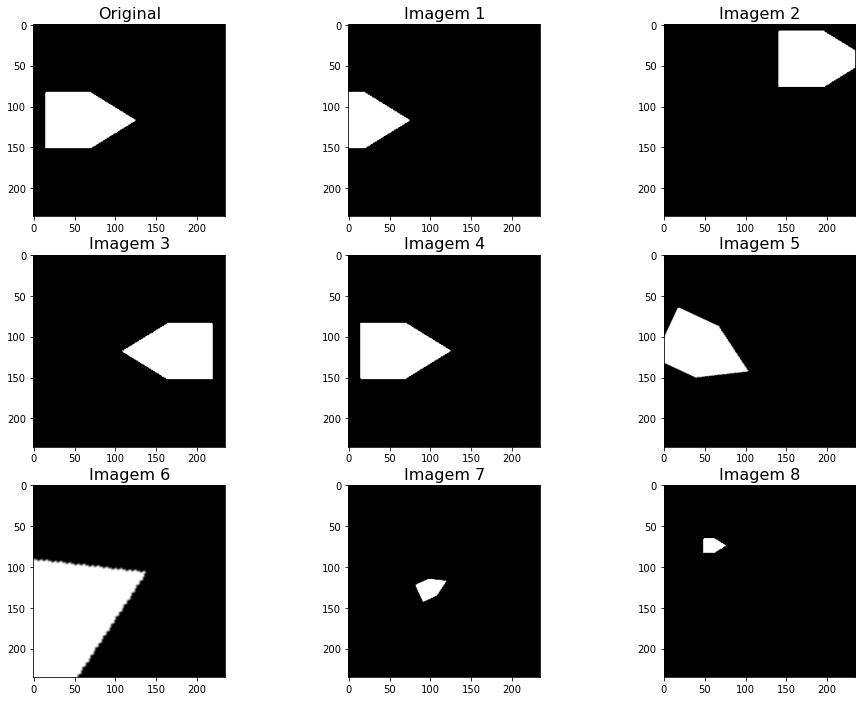

In [9]:
# carregando a imagem e convertendo para a escala de cinza 
im_seta = cv2.imread('images/Seta.tif')
im_seta = cv2.cvtColor(im_seta, cv2.COLOR_BGR2GRAY)
im_seta = cv2.threshold(im_seta, 127.5, 255, cv2.THRESH_BINARY)[1]

# aplicando as transformações lineares na imagem em análise  
im1 = make_translation(im_seta, -50, 0)
im2 = make_translation(im_seta, 125, -75)
im3 = make_reflection(im_seta, 'x')
im4 = make_reflection(im_seta, 'y')
im5 = make_rotation(im_seta, 59, 78, -25, 1)
im6 = make_rotation(im_seta, 118, 118, 25, 3)
im7 = make_rotation(im_seta, 118, 118, 25, 1/3)
im8 = make_rotation(im_seta, 59, 59, 0, 1/4)

fig, axs = plt.subplots(nrows = 3, ncols = 3, figsize=(16, 12))

# primeira figura da subplotagem
axs[0][0].imshow(im_seta, cmap="gray")
axs[0][0].set_title("Original", fontsize = 16)

# segunda figura da subplotagem
axs[0][1].imshow(im1, cmap="gray")
axs[0][1].set_title("Imagem 1", fontsize = 16)

# terceira figura da subplotagem
axs[0][2].imshow(im2, cmap="gray")
axs[0][2].set_title("Imagem 2", fontsize = 16)

# quarta figura da subplotagem
axs[1][0].imshow(im3, cmap="gray")
axs[1][0].set_title("Imagem 3", fontsize = 16)

# quinta figura da subplotagem
axs[1][1].imshow(im4, cmap="gray")
axs[1][1].set_title("Imagem 4", fontsize = 16)

# sexta figura da subplotagem
axs[1][2].imshow(im5, cmap="gray")
axs[1][2].set_title("Imagem 5", fontsize = 16)

# sétima figura da subplotagem
axs[2][0].imshow(im6, cmap="gray")
axs[2][0].set_title("Imagem 6", fontsize = 16)

# oitava figura da subplotagem
axs[2][1].imshow(im7, cmap="gray")
axs[2][1].set_title("Imagem 7", fontsize = 16)

# nona figura da subplotagem
axs[2][2].imshow(im8, cmap="gray")
axs[2][2].set_title("Imagem 8", fontsize = 16)

* **<span style="color:green">Legenda:</span>**

    * <span style="color:green">**Imagem 1**: Translação de -50 pixels na horizontal e   0 pixels na vertical.</span>
    * <span style="color:green">**Imagem 2**: Translação de 125 pixels na horizontal e -75 pixels na vertical.</span>
    * <span style="color:green">**Imagem 3**: Reflexão horizontal.</span>
    * <span style="color:green">**Imagem 4**: Reflexão vertical.</span>
    * <span style="color:green">**Imagem 5**: Rotação de -25° com relação ao ponto (x =  59, y =  78) e escala   1.</span>
    * <span style="color:green">**Imagem 6**: Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala   3.</span>
    * <span style="color:green">**Imagem 7**: Rotação de  25° com relação ao ponto (x = 118, y = 118) e escala 1/3.</span>
    * <span style="color:green">**Imagem 8**: Rotação de   0° com relação ao ponto (x =  59, y =  59) e escala 1/4.</span>

* <span style="color:green">Esses conjuntos de transformações na imagem em que a sua geometria é alterada sem modificar os valores reais de pixel é comumente referido como transformação “geométrica”. No geral, foi utilizado diversas transformações, mas os valores reais dos pixels permaneceram inalterados. Tais procedimentos podem variar de acordo com a forma e a finalidade das matrizes de transformação.</span>

## <span style="color:brown">3. Dilatação e Erosão</span> <a class="anchor" id="3"></a>
***

A partir de um elemento estruturante é possível utilizar funções do OpenCV para realizar as transformações morfológicas de erosão (1) e dilatação (2). A sintaxe das funções é: 

 1. `dst_img = cv2.erode( src_img, kernel, iterations = 1 )`    
 2. `dst_img = cv2.dilate( src_img, kernel, iterations = 1 )`   

* **Descrição:**  
    * **dst_img** representa a imagem de saída;
    * **src_img** representa a imagem de entrada;
    * **kernel** representa o elemento estruturante;
    * **iterations** corresponde ao número de vezes que a operação deve ser repetida.

Elementos estruturantes podem ser produzidos a partir de arrays do numpy.

* <span style="color:blue">**e. Carregue a imagem 'text.tif' e utilize o elemento estruturante abaixo para produzir uma versão dilatada da imagem e outra versão erodida. Comente os resultados encontrados.**</span>
 * `kernel = np.array( [ [1, 0, 1], [0, 1, 0], [1, 0, 1] ], dtype = np.uint8 )`

Text(0.5, 1.0, 'Imagem Erodida')

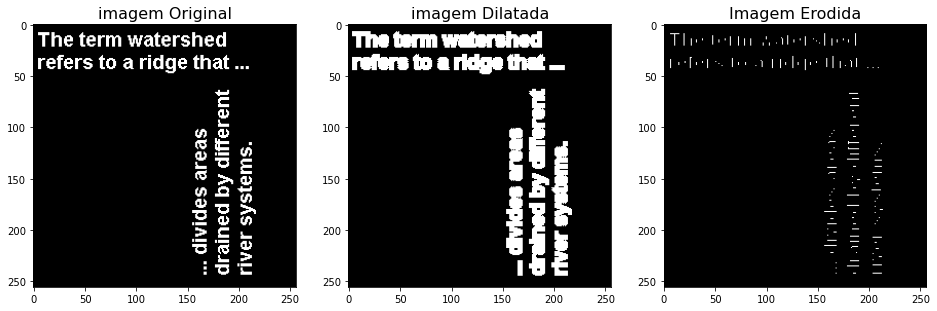

In [10]:
# carregando a imagem na escala de cinza
im_text = cv2.imread('images/text.tif')
im_text = cv2.cvtColor(im_text, cv2.COLOR_BGR2GRAY)
im_text = cv2.threshold(im_text, 127.5, 255, cv2.THRESH_BINARY)[1]

# definindo o elemento estruturante 
kernel = np.array([[1, 0, 1], [0, 1, 0], [1, 0, 1]], dtype=np.uint8)

# aplicando uma dilatação utilizando o elemento estrutural
im_dilate = cv2.dilate(im_text, kernel, iterations=1)
# aplicando uma erosão utilizando o elemento estrutural
im_erode = cv2.erode(im_text, kernel, iterations=1)

fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 12))

# primeira figura da subplotagem
axs[0].imshow(im_text, cmap="gray")
axs[0].set_title("imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[1].imshow(im_dilate, cmap="gray")
axs[1].set_title("imagem Dilatada", fontsize = 16)

# terceira figura da subplotagem
axs[2].imshow(im_erode, cmap="gray")
axs[2].set_title("Imagem Erodida", fontsize = 16)

* <span style="color:green">**Efeitos da dilatação e erosão nas imagens em análise**:</span>
    * <span style="color:green">O efeito de aplicar a dilatação na imagem acima "engordou" os detalhes presentes na borda dos caracteres (considerando-os como partículas), o que dificultou a compreensão do texto presente na imagem.</span>
    * <span style="color:green">O efeito de aplicar a erosão na imagem acima removeu os detalhes presentes na borda dos caracteres (considerando-os como partículas), o que os descaracterizou completamente.</span>

Elementos estruturantes também podem ser produzidos pela função **getStructuringElement** do OpenCV:

 * `kernel = cv2.getStructuringElement( FLAG, (W,H) )`

* **Descrição:**
    * **kernel** representa o elemento estruturante;
    * **(W, H)** é uma tupla com as dimensões do elemento estruturante;
    * **FLAG** é um parâmetro que indica o tipo de elemento estruturante produzido, pode ser:
        * **cv2.MORPH_RECT** produz um elemento retangular;
        * **cv2.MORPH_ELLIPSE** produz um elemento elíptico;
        * **cv2.MORPH_CROSS** produz um elemento em forma de cruz;

Text(0.5, 1.0, 'cv2.MORPH_CROSS')

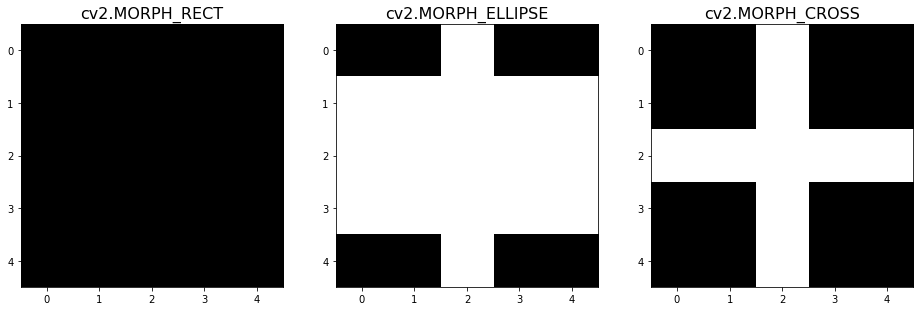

In [11]:
H = 5
W = 5

# Plots
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 12))

# Primeira Subfigura da primeira linha
kernel = cv2.getStructuringElement( cv2.MORPH_RECT, (W,H) )
axs[0].imshow(kernel, cmap="gray")
axs[0].set_title("cv2.MORPH_RECT", fontsize = 16)

# Segunda Subfigura da primeira linha
kernel = cv2.getStructuringElement( cv2.MORPH_ELLIPSE, (W,H) )
axs[1].imshow(kernel, cmap="gray")
axs[1].set_title("cv2.MORPH_ELLIPSE", fontsize = 16)

# Terceira Subfigura da primeira linha
kernel = cv2.getStructuringElement( cv2.MORPH_CROSS, (W,H) )
axs[2].imshow(kernel, cmap="gray")
axs[2].set_title("cv2.MORPH_CROSS", fontsize = 16)

Ou ainda utilizando as funções do Scikit-Image:

 * `kernel = skimage.morphology.square( H )`
 * `kernel = skimage.morphology.rectangle( H, W )`
 * `kernel = skimage.morphology.diamond( H )`
 * `kernel = skimage.morphology.disk( R )`
 * `kernel = skimage.morphology.octagon( M, N )`
 * `kernel = skimage.morphology.star( A)`

Text(0.5, 1.0, 'Star')

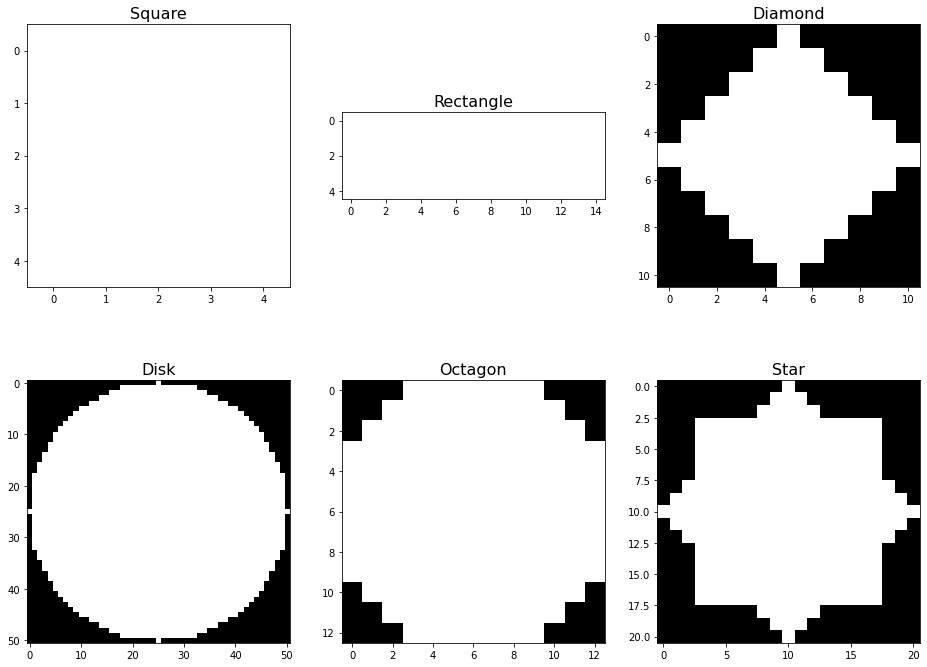

In [12]:
H =  5 # Altura do quadrado/retângulo e lado do diamante
W = 15 # Largura do retângulo
R = 25 # Raio do disco
M =  7 # Comprimento dos lados retos do octágono
N =  3 # Comprimento dos lados inclinados do octágono
A =  7 # Variável que controla o tamanho da estrela, o quadrado que a contém tem lado H = 2*a + 1 + 2*floor(a / 2)

# Plots
fig, axs = plt.subplots(nrows = 2, ncols = 3, figsize=(16, 12))

# Primeira Subfigura da primeira linha
kernel = skimage.morphology.square( H )
axs[0][0].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[0][0].set_title("Square", fontsize = 16)

# Segunda Subfigura da primeira linha
kernel = skimage.morphology.rectangle( H, W )
axs[0][1].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[0][1].set_title("Rectangle", fontsize = 16)

# Terceira Subfigura da primeira linha
kernel = skimage.morphology.diamond( H )
axs[0][2].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[0][2].set_title("Diamond", fontsize = 16)

# Primeira Subfigura da segunda linha
kernel = skimage.morphology.disk( R )
axs[1][0].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[1][0].set_title("Disk", fontsize = 16)

# Segunda Subfigura da segunda linha
kernel = skimage.morphology.octagon( M, N )
axs[1][1].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[1][1].set_title("Octagon", fontsize = 16)

# Terceira Subfigura da segunda linha
kernel = skimage.morphology.star( A )
axs[1][2].imshow(kernel, vmin=0, vmax=1, cmap="gray")
axs[1][2].set_title("Star", fontsize = 16)

Text(0.5, 1.0, 'Linha Vertical de 5 pontos')

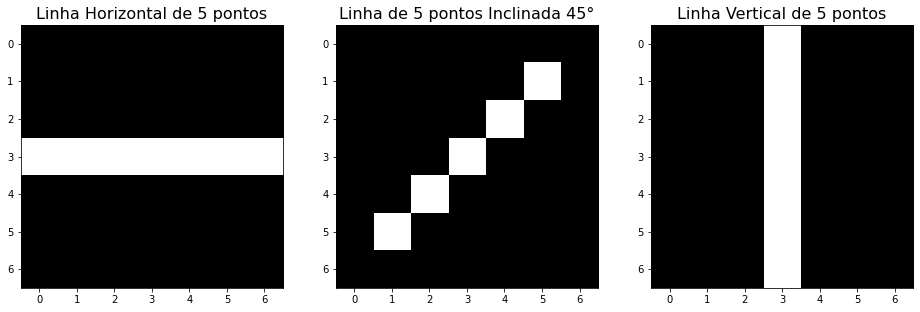

In [13]:
# Elemento estruturante correspondente a uma linha horizontal
orig_kernel  = np.zeros( (7, 7), dtype = np.uint8 )
orig_kernel[3, :] = 1

# Matriz de rotação para 45°
M = cv2.getRotationMatrix2D( (3, 3),  45 ,   1)

# Plots
fig, axs = plt.subplots(nrows = 1, ncols = 3, figsize=(16, 12))

# Primeira Subfigura da primeira linha
axs[0].imshow(orig_kernel, cmap="gray")
axs[0].set_title("Linha Horizontal de 5 pontos", fontsize = 16)

# Segunda Subfigura da primeira linha
kernel = cv2.warpAffine(orig_kernel, M, (7, 7))
axs[1].imshow(kernel, cmap="gray")
axs[1].set_title("Linha de 5 pontos Inclinada 45°", fontsize = 16)

# Terceira Subfigura da primeira linha
kernel = cv2.warpAffine(kernel, M, (7, 7))
axs[2].imshow(kernel, cmap="gray")
axs[2].set_title("Linha Vertical de 5 pontos", fontsize = 16)

* <span style="color:blue">**f. Usando as funções mostradas, gere os seguintes elementos estruturantes para dilatar a imagem 'text.tif'. Mostre as imagens resultantes e comente os resultados encontrados.**</span>
 * <span style="color:blue">Disco de raio 9;</span>
 * <span style="color:blue">Estrela com A = 13;</span>
 * <span style="color:blue">Linha vertical de 11 pontos de tamanho;</span>
 * <span style="color:blue">Linha vertical de 9 pontos de tamanho;</span>

Text(0.5, 1.0, 'Linha Vertical de 9 pontos')

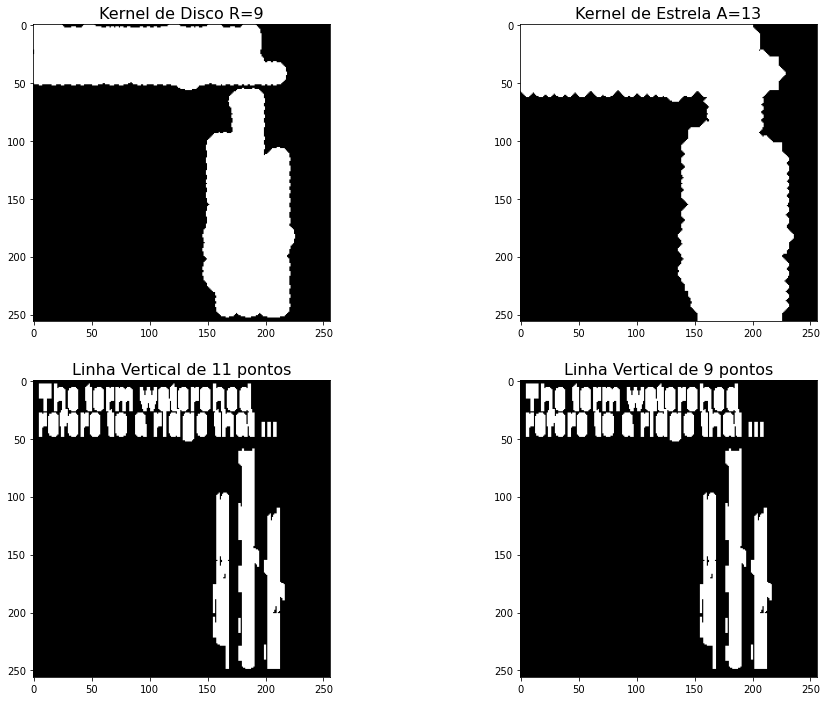

In [14]:
# gerando elementos estruturantes 
disk_kernel = kernel = skimage.morphology.disk(9)
star_kernel = skimage.morphology.star(13)
vertical_line1  = np.zeros( (11, 11), dtype = np.uint8 )
vertical_line1[:, 5] = 1
vertical_line2  = np.zeros( (9, 9), dtype = np.uint8 )
vertical_line2[:, 4] = 1

# aplicando a dilatação na imagem utilizando os diversos elementos estruturantes propostos 
im1_dilate = cv2.dilate(im_text, disk_kernel, iterations=1)
im2_dilate = cv2.dilate(im_text, star_kernel, iterations=1)
im3_dilate = cv2.dilate(im_text, vertical_line1, iterations=1)
im4_dilate = cv2.dilate(im_text, vertical_line2, iterations=1)

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16,12))

# primeira figura da subplotagem
axs[0, 0].imshow(im1_dilate, cmap="gray")
axs[0, 0].set_title("Kernel de Disco R=9", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im2_dilate, cmap="gray")
axs[0, 1].set_title("Kernel de Estrela A=13", fontsize = 16) 

# terceira figura da subplotagem
axs[1, 0].imshow(im3_dilate, cmap="gray")
axs[1, 0].set_title("Linha Vertical de 11 pontos", fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im3_dilate, cmap="gray")
axs[1, 1].set_title("Linha Vertical de 9 pontos", fontsize = 16) 

* <span style="color:green">**Observando as imagens dilatadas em análise, é perceptível que**:
    * <span style="color:green">As imagens foram dilatadas e os caracteres presentes nas imagens foram "engordadas" nas bordas influenciada pela forma e o tamanho do elemento estruturante (kernel).</span>
    * <span style="color:green">Os elementos presentes na imagem (caracteres) fora unidos, uma das características do procedimento de dilatação.</span>

* <span style="color:blue">**g. Realize a erosão na imagem 'wirebond_mask.tif' com um elemento estruturante formado por um diamante de raio 6. Varie o tamanho (raio) do elemento estruturante para 4 e 8 e mostre os resultados. Comente os resultados encontrados.**</span>

Text(0.5, 1.0, 'Erosão - E.E: diamante R:8')

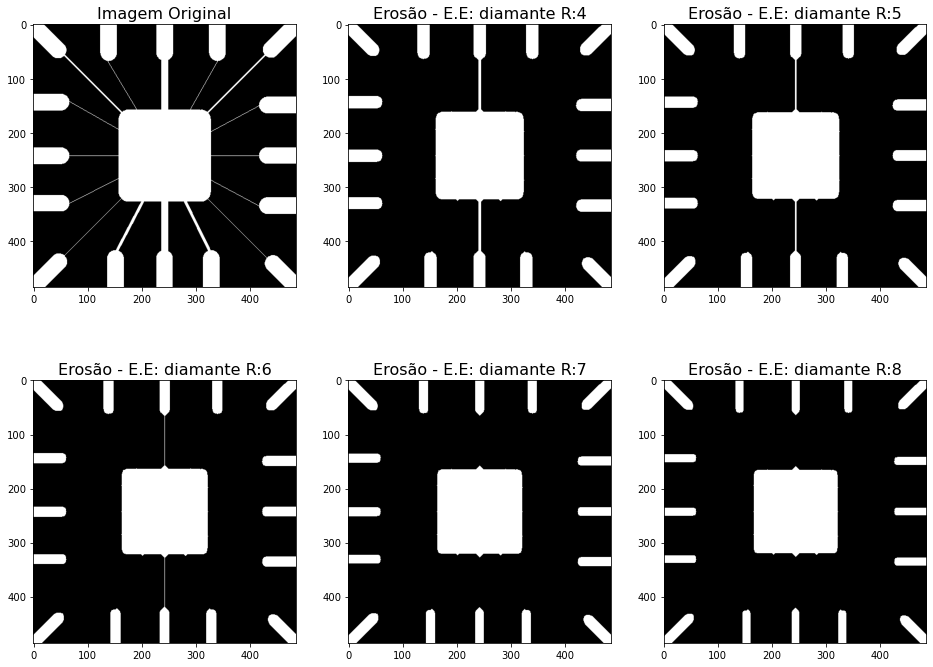

In [15]:
# carregando a imagem na escala de cinza
im_wirebond = cv2.imread('images/wirebond_mask.tif')
im_wirebond = cv2.cvtColor(im_wirebond, cv2.COLOR_BGR2GRAY)
im_wirebond = cv2.threshold(im_wirebond, 127.5, 255, cv2.THRESH_BINARY)[1]

# utilizando o elemento estruturante no formato de diamante e variando o raio desse elemento  
kernel1 = skimage.morphology.diamond(4)
kernel2 = skimage.morphology.diamond(5)
kernel3 = skimage.morphology.diamond(6)
kernel4 = skimage.morphology.diamond(7)
kernel5 = skimage.morphology.diamond(8)

# aplicando a erosão na imagem com os diversos elementos estruturantes gerados  
erode_im1 = cv2.erode(im_wirebond, kernel1, iterations=1)
erode_im2 = cv2.erode(im_wirebond, kernel2, iterations=1)
erode_im3 = cv2.erode(im_wirebond, kernel3, iterations=1)
erode_im4 = cv2.erode(im_wirebond, kernel4, iterations=1)
erode_im5 = cv2.erode(im_wirebond, kernel5, iterations=1)

fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(16,12))

# primeira figura da subplotagem
axs[0, 0].imshow(im_wirebond, cmap="gray")
axs[0, 0].set_title("Imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(erode_im1, cmap="gray")
axs[0, 1].set_title("Erosão - E.E: diamante R:4", fontsize = 16)

# terceira figura da subplotagem
axs[0, 2].imshow(erode_im2, cmap="gray")
axs[0, 2].set_title("Erosão - E.E: diamante R:5", fontsize = 16)

# quarta figura da subplotagem
axs[1, 0].imshow(erode_im3, cmap="gray")
axs[1, 0].set_title("Erosão - E.E: diamante R:6", fontsize = 16)

# quinta figura da subplotagem
axs[1, 1].imshow(erode_im4, cmap="gray")
axs[1, 1].set_title("Erosão - E.E: diamante R:7", fontsize = 16)

# sexta figura da subplotagem
axs[1, 2].imshow(erode_im5, cmap="gray")
axs[1, 2].set_title("Erosão - E.E: diamante R:8", fontsize = 16)

* <span style="color:green">**Observando as imagens dilatadas em análise, é perceptível que:**</span>
    * <span style="color:green">Ao realizar a erosão na imagem acima, foi possível observar a influência do elemento estruturante (kernel) para cada um dos resultados obtidos. O tamanho do raio desse elemento implica nas saídas de cada uma das imagens. Quanto maior for as dimensões do elemento estruturante, mas partículas são erodidas, considerando que as partículas possuem um tamanho menor em relação ao kernel.</span>

## <span style="color:brown">4. Abertura e Fechamento</span> <a class="anchor" id="4"></a>
***

A partir de um elemento estruturante é possível utilizar funções do OpenCV para realizar as transformações morfológicas de abertura e fechamento a partir de uma mesma função. Sua sintaxe é: 

 * `dst_img = cv2.morphologyEx(src_img, FLAG, kernel)`       

* **Descrição:**
    * **dst_img** representa a imagem de saída;
    * **src_img** representa a imagem de entrada;
    * **kernel** representa o elemento estruturante;
    * **FLAG** é um parâmetro que indica a transformação realizada, pode ser:
        * **cv2.MORPH_OPEN** realiza uma operação de abertura;
        * **cv2.MORPH_CLOSE** realiza uma operação de fechamento;
        * **cv2.MORPH_GRADIENT** realiza uma operação de gradiente morfológico (diferença entre as versões dilatada e erodida de uma imagem);
        * **cv2.MORPH_TOPHAT** realiza uma operação de Tophat (diferença entre a imagem original e sua versão após abertura);
        * **cv2.MORPH_BLACKHAT** realiza uma operação de Blackhat (diferença entre a versão da imagem após fechamento e a original);

* <span style="color:blue">**h. Aplicar os seguintes filtros morfológicos na imagem 'shapes.tif':**</span>
    * <span style="color:blue">Abertura, utilizando um elemento estruturante quadrado (square) de altura 10.</span>
    * <span style="color:blue">Fechamento, utilizando um elemento estruturante quadrado de altura 10.</span>
    * <span style="color:blue">Uma abertura seguida de um fechamento, um elemento estruturante quadrado de altura 10.</span>
    * <span style="color:blue">Repetir o item anterior variando a altura do elemento estruturante para 5 e depois para 15. Analise os resultados encontrados.</span>

    * <span style="color:blue">Comente os resultados encontrados em todos os itens acima.</span>

In [16]:
# carregando a imagem em escala de cinza
shapes_im = cv2.imread('images/shapes.tif')
shapes_im = cv2.cvtColor(shapes_im, cv2.COLOR_BGR2GRAY)
shapes_im = cv2.threshold(shapes_im, 127.5, 255, cv2.THRESH_BINARY)[1]

In [17]:
# configurando os elementos estruturantes 
square_kernel1 = skimage.morphology.square(10)
square_kernel2 = skimage.morphology.square(5)
square_kernel3 = skimage.morphology.square(15)

Text(0.5, 0, 'E.E - Quadrado H:10')

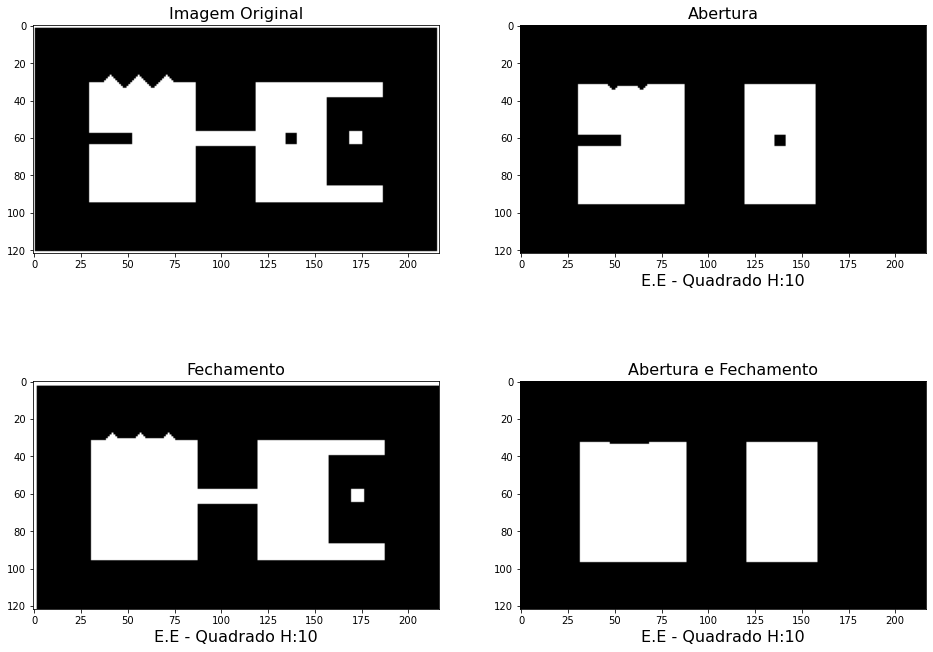

In [18]:
# aplicando os procedimentos de morfologia matemática nas imagens
im1 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel1)
im2 = cv2.morphologyEx(shapes_im, cv2.MORPH_CLOSE, square_kernel1)
im3 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel1) 
im3 = cv2.morphologyEx(im3, cv2.MORPH_CLOSE, square_kernel1)  

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16,12))

# primeira figura da subplotagem
axs[0, 0].imshow(shapes_im, cmap="gray")
axs[0, 0].set_title("Imagem Original", fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im1, cmap="gray")
axs[0, 1].set_title("Abertura", fontsize = 16)
axs[0, 1].set_xlabel('E.E - Quadrado H:10', fontsize = 16) 

# terceira figura da subplotagem
axs[1, 0].imshow(im2, cmap="gray")
axs[1, 0].set_title("Fechamento", fontsize = 16)
axs[1, 0].set_xlabel('E.E - Quadrado H:10', fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im3, cmap="gray")
axs[1, 1].set_title("Abertura e Fechamento", fontsize = 16)
axs[1, 1].set_xlabel('E.E - Quadrado H:10', fontsize = 16) 

* <span style="color:green">A abertura na imagem realiza uma suavização do contorno, retira intruzões, tornando menos agudos os cantos.</span>
* <span style="color:green">O fechamento na imagem suaviza seções do contorno, preenchimento de buracos e união de furos e falhas do contorno.</span>
* <span style="color:green">O procedimento de abertura sucedido de fechamento é equivalmente a suavizar os elementos da imagem e sequencialmente corrigir as falhas do contorno.</span>

Text(0.5, 0, 'E.E - Quadrado H:15')

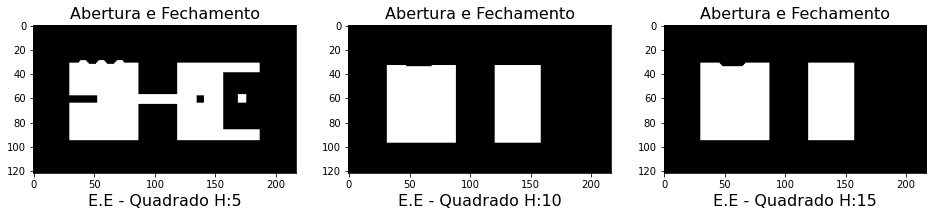

In [19]:
# aplicando os procedimentos de morfologia matemática nas imagens
im4 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel2) 
im4 = cv2.morphologyEx(im4, cv2.MORPH_CLOSE, square_kernel2)  
im5 = cv2.morphologyEx(shapes_im, cv2.MORPH_OPEN, square_kernel3) 
im5 = cv2.morphologyEx(im5, cv2.MORPH_CLOSE, square_kernel3)  

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(16,12))


# primeira figura da subplotagem
axs[0].imshow(im4, cmap="gray")
axs[0].set_title("Abertura e Fechamento", fontsize = 16)
axs[0].set_xlabel('E.E - Quadrado H:5', fontsize = 16)

# primeira figura da subplotagem
axs[1].imshow(im3, cmap="gray")
axs[1].set_title("Abertura e Fechamento", fontsize = 16)
axs[1].set_xlabel('E.E - Quadrado H:10', fontsize = 16)

# primeira figura da subplotagem
axs[2].imshow(im5, cmap="gray")
axs[2].set_title("Abertura e Fechamento", fontsize = 16)
axs[2].set_xlabel('E.E - Quadrado H:15', fontsize = 16) 

* <span style="color:green">O tamanho do elemento estruturante influência na forma como os elementos tem seus cantos suavizados seguidos da correção de falhas de contorno. Quanto maior for o elemento estruturante, mais partículas são modificadas na imagem, transformando-as mais bruscamente.</span>

* <span style="color:blue">**i. Aplique os seguintes filtros morfológicos na imagem 'finger.jpg':**</span>
    * <span style="color:blue">Abertura, utilizando um elemento estruturante em formato de disco de raio 1.</span>
    * <span style="color:blue">Fechamento, utilizando um elemento estruturante em formato de disco de raio 1.</span>
    * <span style="color:blue">Uma abertura seguida de um fechamento com um elemento estruturante em formato de disco de raio 1.</span>
    * <span style="color:blue">Um fechamento seguido de uma abertura com um elemento estruturante em formato de disco de raio 1.</span>
    * <span style="color:blue">Comente os resultados encontrados em todos os itens acima.</span>

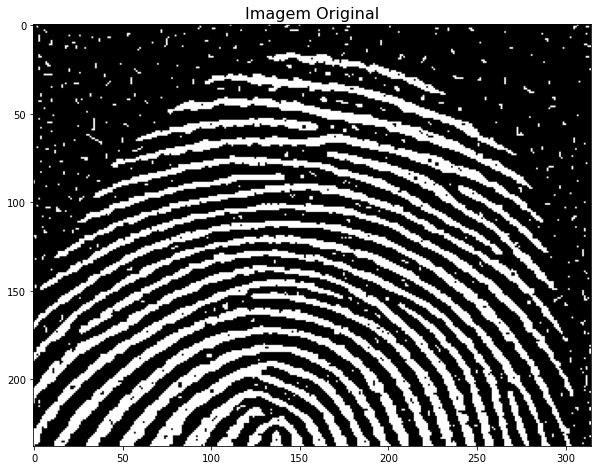

In [20]:
# carregando a imagem em escala de cinza
finger_im = cv2.imread('images/finger.jpg')
finger_im = cv2.cvtColor(finger_im, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(10,10))
plt.title('Imagem Original', size=16)
plt.imshow(finger_im, cmap='gray') 

Text(0.5, 0, 'E.E - Disco R:1')

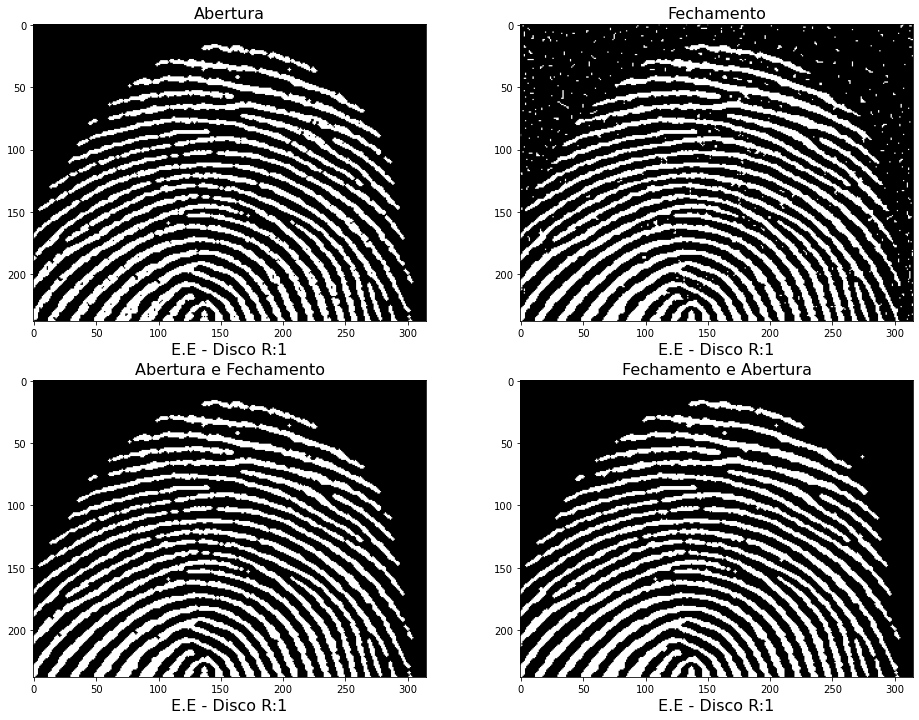

In [21]:
# configurando o elemento estruturante 
disk_kernel = skimage.morphology.disk(1) 

# aplicando os procedimentos de morfologia matemática nas imagens
im1 = cv2.morphologyEx(finger_im, cv2.MORPH_OPEN, disk_kernel) 
im2 = cv2.morphologyEx(finger_im, cv2.MORPH_CLOSE, disk_kernel) 
im3 = cv2.morphologyEx(finger_im, cv2.MORPH_OPEN, disk_kernel) 
im3 = cv2.morphologyEx(im3, cv2.MORPH_CLOSE, disk_kernel) 
im4 = cv2.morphologyEx(finger_im, cv2.MORPH_CLOSE, disk_kernel) 
im4 = cv2.morphologyEx(im4, cv2.MORPH_OPEN, disk_kernel)  

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(16,12))

# primeira figura da subplotagem
axs[0, 0].imshow(im1, cmap="gray")
axs[0, 0].set_title("Abertura", fontsize = 16)
axs[0, 0].set_xlabel('E.E - Disco R:1', fontsize = 16)

# segunda figura da subplotagem
axs[0, 1].imshow(im2, cmap="gray")
axs[0, 1].set_title("Fechamento", fontsize = 16)
axs[0, 1].set_xlabel('E.E - Disco R:1', fontsize = 16)

# terceira figura da subplotagem
axs[1, 0].imshow(im3, cmap="gray")
axs[1, 0].set_title("Abertura e Fechamento", fontsize = 16)
axs[1, 0].set_xlabel('E.E - Disco R:1', fontsize = 16)

# quarta figura da subplotagem
axs[1, 1].imshow(im4, cmap="gray")
axs[1, 1].set_title("Fechamento e Abertura", fontsize = 16)
axs[1, 1].set_xlabel('E.E - Disco R:1', fontsize = 16)  

* <span style="color:green">Na primeira imagem, o procedimento de abertura permitiu extrair a maioria dos ruídos na imagem biométrica do polegar.</span>
* <span style="color:green">Na segunda imagem, o procedimento de fechamento corrigiu as falhas presentes nos traços da digital do polegar, mas não removeu os ruídos presentes na imagem.</span>
* <span style="color:green">Comparando a terceira imagem com a quarta imagem, o procedimento de realizar a abertura sucedida de fechamento na digital do polegar permitiu obter a melhor imagem dentre as 4 analisadas. Isso porque os ruídos foram removidos e a qualidade dos traços foram preservadas, permitindo uma imagem mais adequada para identificação biométrica do usuário.</span>

***
![MELHOR DISCIPLINA <3](https://user-images.githubusercontent.com/58775072/131049638-47ea29a5-0b8c-4b8d-a6c0-bd5ede605752.gif)